In [1]:
from pathlib import Path
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import cv2

In [2]:
# Inspect some sample data
root = Path("data/Task06_Lung/imagesTr")
label = Path("data/Task06_Lung/labelsTr/")

In [3]:
# Load a sample NIfTI and its corresponding label mask
def change_img_to_label_path(path):
    """
    Replaces imagesTr with labelsTr
    """
    parts = list(path.parts)  # get all directories whithin the path
    parts[parts.index("imagesTr")] = "labelsTr"  # Replace imagesTr with labelsTr
    return Path(*parts)  # Combine list back into a Path object

In [4]:
sample_path = list(root.glob("lung*"))[2]  # Choose a subject
sample_path_label = change_img_to_label_path(sample_path)

sample_path, sample_path_label

(WindowsPath('data/Task06_Lung/imagesTr/lung_004.nii.gz'),
 WindowsPath('data/Task06_Lung/labelsTr/lung_004.nii.gz'))

In [5]:
data = nib.load(sample_path)
label = nib.load(sample_path_label)

ct = data.get_fdata()
mask = label.get_fdata().astype(np.uint8)

In [6]:
nib.aff2axcodes(data.affine)

('L', 'A', 'S')

In [7]:
ct.shape

(512, 512, 276)

In [ ]:
from celluloid import Camera
from IPython.display import HTML

fig = plt.figure()
camera = Camera(fig)

for i in range(ct.shape[2]):
    plt.imshow(ct[:, :, i], cmap='bone')
    mask_ = np.ma.masked_where(mask[:, :, i] == 0, mask[:, :, i])
    plt.imshow(mask_, alpha=0.5, cmap='autumn')
    plt.axis('off')
    camera.snap()

animation = camera.animate()

In [9]:
HTML(animation.to_html5_video())

## Preprocessing

In [ ]:
all_files = list(sorted(root.glob('lung*')))

len(all_files)

63

In [14]:
from sklearn.model_selection import train_test_split

save_root = Path('processed/Task06_Lung')

# Split at the PATIENT level: every patient (one NIfTI volume) goes entirely to train OR val,
# so slices from the same patient can never appear in both sets. (No test split.)
patient_ids = [p.name.replace('.nii.gz', '') for p in all_files]  # e.g. 'lung_001'

train_patients, val_patients = train_test_split(patient_ids,
                                                test_size=0.2,
                                                random_state=42,
                                                shuffle=True)

patient_split = {pid: 'train' for pid in train_patients}
patient_split.update({pid: 'val' for pid in val_patients})

print(f"{len(train_patients)} train patients, {len(val_patients)} val patients")

# Create output directories for both splits
split_paths = {}
for split in ['train', 'val']:
    split_paths[split] = {
        'data': save_root / split / 'data',
        'masks': save_root / split / 'masks',
    }
    split_paths[split]['data'].mkdir(parents=True, exist_ok=True)
    split_paths[split]['masks'].mkdir(parents=True, exist_ok=True)

# Keep these names, they are used further down in the notebook
train_slice_path = split_paths['train']['data']
train_mask_path = split_paths['train']['masks']
val_slice_path = split_paths['val']['data']
val_mask_path = split_paths['val']['masks']

50 train patients, 13 val patients


In [ ]:
# One record per saved slice: (patient_id, split, slice_name, mask_name, has_tumor)
records = []

for path_to_ct_data in tqdm(all_files):
    patient_id = path_to_ct_data.name.replace('.nii.gz', '')  # e.g. 'lung_001'
    split = patient_split[patient_id]
    out_slice_dir = split_paths[split]['data']
    out_mask_dir = split_paths[split]['masks']

    path_to_label = change_img_to_label_path(path_to_ct_data)

    # Load and extract corresponding data
    ct_data = nib.load(path_to_ct_data).get_fdata()
    label_data = nib.load(path_to_label).get_fdata().astype(np.uint8)

    # Clip volume values between 3071 and -1024
    ct_data = np.clip(a=ct_data, a_max=3071, a_min=-1024)

    # Crop volume and label. Remove the first 30 slices
    ct_data = ct_data[:,:,30:] / 3071
    label_data = label_data[:,:,30:]

    # Loop over the slices in the full volume and store the data and labels in the data/masks directory
    for i in range(ct_data.shape[-1]):
        slice = ct_data[:,:,i]
        mask = label_data[:,:,i]

        # Resize slice and label to common resolution to reduce training time
        slice = cv2.resize(slice, (256, 256))
        mask = cv2.resize(mask, (256, 256), interpolation=cv2.INTER_NEAREST)

        # Name encodes the patient and the slice index within the ORIGINAL volume (i + 30 because of the crop)
        # e.g. lung_001_slice_042.npy / lung_001_mask_042.npy
        slice_idx = i + 30
        slice_name = f'{patient_id}_slice_{slice_idx:03d}'
        mask_name = f'{patient_id}_mask_{slice_idx:03d}'

        np.save(out_slice_dir / slice_name, slice)
        np.save(out_mask_dir / mask_name, mask)

        records.append((patient_id, split, slice_name, mask_name, bool(mask.any())))

In [16]:
# Distribution of classification label (non-tumor slices vs tumor slices) in each split
for split in ['train', 'val']:
    y = np.array([r[4] for r in records if r[1] == split])
    n_patients = len({r[0] for r in records if r[1] == split})
    print(f"{split}: {n_patients} patients, {len(y)} slices, "
          f"non-tumor/tumor slices = {np.unique(y, return_counts=True)}")

train: 50 patients, 12681 slices, non-tumor/tumor slices = (array([False,  True]), array([11429,  1252], dtype=int64))
val: 13 patients, 3086 slices, non-tumor/tumor slices = (array([False,  True]), array([2692,  394], dtype=int64))


In [17]:
# Validate there is no data leakage: train and val must share no patients (and therefore no slices)
train_patient_set = {f.name.split('_slice_')[0] for f in train_slice_path.glob('*.npy')}
val_patient_set = {f.name.split('_slice_')[0] for f in val_slice_path.glob('*.npy')}

assert train_patient_set.isdisjoint(val_patient_set), "Patient leakage between train and val!"
assert train_patient_set == set(train_patients) and val_patient_set == set(val_patients)

train_set = {f.name for f in train_slice_path.glob('*.npy')}
val_set = {f.name for f in val_slice_path.glob('*.npy')}
assert train_set.isdisjoint(val_set)

print(f"OK: {len(train_patient_set)} train patients / {len(val_patient_set)} val patients, no overlap")

OK: 50 train patients / 13 val patients, no overlap


In [19]:
path = Path('processed/Task06_Lung/train')

for i, file in enumerate(sorted(list((path / 'data').glob('*.npy')))[500:1000], start=500):
    slice_data = np.load(file)

    parts = list(file.parts)
    parts[parts.index("data")] = "masks"
    parts[-1] = parts[-1].replace('slice', 'mask')
    mask_file = Path(*parts)

    mask = np.load(mask_file)

    if mask.sum() > 200:
        print(i, end=' ')

638 639 640 641 642 643 644 645 646 647 648 

In [20]:
# Pick a slice by position in the sorted file list (names now look like lung_XXX_slice_YYY.npy)
sample_file = sorted((path / 'data').glob('*.npy'))[640]
print(sample_file.name)
slice_data = np.load(sample_file)
mask = np.load(path / 'masks' / sample_file.name.replace('slice', 'mask'))

lung_005_slice_166.npy


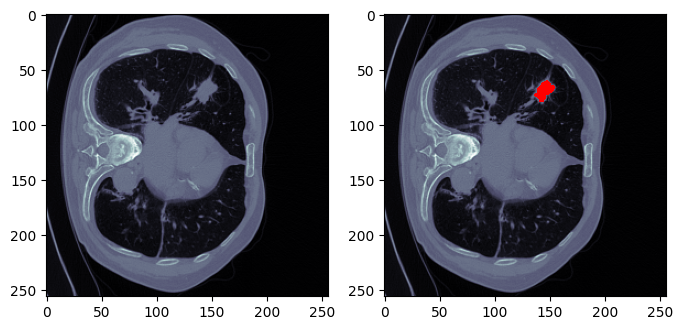

In [21]:
# Plot everything
fig, axis = plt.subplots(nrows=1, ncols=2, figsize=(8, 8))
axis[0].imshow(slice_data, cmap="bone")
mask_ = np.ma.masked_where(mask == 0, mask)
axis[1].imshow(slice_data, cmap="bone")
axis[1].imshow(mask_, cmap="autumn")

## Dataset Creation

In [22]:
from pathlib import Path
import torch
import numpy as np
import imgaug
from imgaug.augmentables.segmaps import SegmentationMapsOnImage

In [23]:
class LungDataset(torch.utils.data.Dataset):
    def __init__(self, root, augment_params):
        super().__init__()
        self.all_files = self.extract_files(root)
        self.augment_params = augment_params

    @staticmethod
    def extract_files(root):
        """
        Extract the paths to all slices given the root path (ends with train or val)
        Sorted so the order is deterministic: weights built from one instance
        stay aligned with every other instance.
        """
        slice_path = root / "data"  # Get the slices for all subjects

        return sorted(slice_path.glob("*"))

    @staticmethod
    def change_img_to_label_path(path):
        """
        Replace data with mask to get the masks
        """
        parts = list(path.parts)
        parts[parts.index("data")] = "masks"
        parts[-1] = parts[-1].replace('slice', 'mask')

        return Path(*parts)

    def augment(self, slice, mask):
        """
        Augments slice and segmentation mask in the exact same way
        Note the manual seed initialization
        """
        # Fix for https://discuss.pytorch.org/t/dataloader-workers-generate-the-same-random-augmentations/28830/2
        random_seed = torch.randint(0, 1000000, (1,))[0].item()
        imgaug.seed(random_seed)

        mask = SegmentationMapsOnImage(mask, mask.shape)
        slice_aug, mask_aug = self.augment_params(image=slice, segmentation_maps=mask)
        mask_aug = mask_aug.get_arr()

        return slice_aug, mask_aug

    def __len__(self):
        """
        Return the length of the dataset (length of all files)
        """
        return len(self.all_files)


    def __getitem__(self, idx):
        """
        Given an index return the (augmented) slice and corresponding mask
        Add another dimension for pytorch
        """
        file_path = self.all_files[idx]
        mask_path = self.change_img_to_label_path(file_path)
        slice_data = np.load(file_path).astype(np.float32)
        mask = np.load(mask_path)

        if self.augment_params:
            slice_data, mask = self.augment(slice_data, mask)

        return np.expand_dims(slice_data, 0), np.expand_dims(mask, 0)

In [24]:
import matplotlib.pyplot as plt
import imgaug.augmenters as iaa

seq = iaa.Sequential([
    iaa.Fliplr(0.5),
    iaa.Flipud(0.5),
    iaa.LinearContrast((0.75, 1.25)),
    iaa.Affine(translate_percent=(0.15),
               scale=(0.85, 1.15),
               rotate=(-45, 45)),
    iaa.ElasticTransformation()
])

In [25]:
path = Path('processed/Task06_Lung/train')
dataset = LungDataset(path, seq)

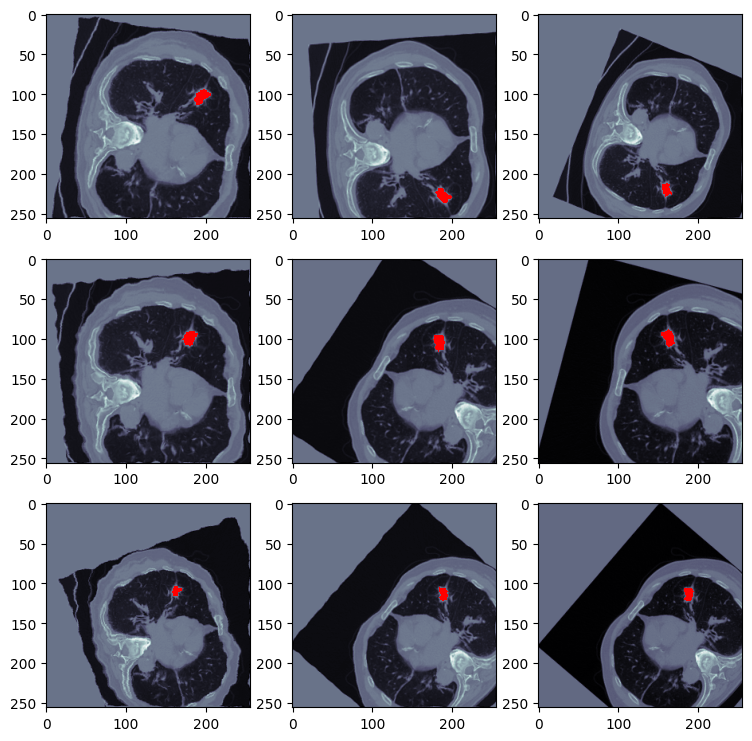

In [26]:
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(9, 9))

for i in range(3):
    for j in range(3):
        slice_data, mask = dataset[640]
        mask_ = np.ma.masked_where(mask == 0, mask)
        axes[i][j].imshow(slice_data[0], cmap='bone')
        axes[i][j].imshow(mask_[0], cmap='autumn')

In [40]:
%%writefile dataset.py
from pathlib import Path
import torch
import numpy as np
import imgaug
from imgaug.augmentables.segmaps import SegmentationMapsOnImage

class LungDataset(torch.utils.data.Dataset):
    def __init__(self, root, augment_params):
        super().__init__()
        self.all_files = self.extract_files(root)
        self.augment_params = augment_params

    @staticmethod
    def extract_files(root):
        """
        Extract the paths to all slices given the root path (ends with train or val)
        Sorted so the order is deterministic: weights built from one instance
        stay aligned with every other instance.
        """
        slice_path = root / "data"  # Get the slices for all subjects

        return sorted(slice_path.glob("*"))

    @staticmethod
    def change_img_to_label_path(path):
        """
        Replace data with mask to get the masks
        """
        parts = list(path.parts)
        parts[parts.index("data")] = "masks"
        parts[-1] = parts[-1].replace('slice', 'mask')

        return Path(*parts)

    def augment(self, slice, mask):
        """
        Augments slice and segmentation mask in the exact same way
        Note the manual seed initialization
        """
        # Fix for https://discuss.pytorch.org/t/dataloader-workers-generate-the-same-random-augmentations/28830/2
        random_seed = torch.randint(0, 1000000, (1,))[0].item()
        imgaug.seed(random_seed)

        mask = SegmentationMapsOnImage(mask, mask.shape)
        slice_aug, mask_aug = self.augment_params(image=slice, segmentation_maps=mask)
        mask_aug = mask_aug.get_arr()

        return slice_aug, mask_aug

    def __len__(self):
        """
        Return the length of the dataset (length of all files)
        """
        return len(self.all_files)


    def __getitem__(self, idx):
        """
        Given an index return the (augmented) slice and corresponding mask
        Add another dimension for pytorch
        """
        file_path = self.all_files[idx]
        mask_path = self.change_img_to_label_path(file_path)
        slice_data = np.load(file_path).astype(np.float32)
        mask = np.load(mask_path)

        if self.augment_params:
            slice_data, mask = self.augment(slice_data, mask)

        return np.expand_dims(slice_data, 0), np.expand_dims(mask, 0)

Writing dataset.py


## U-Net Model Implementation

In [27]:
import torch

class DoubleConv(torch.nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.step = torch.nn.Sequential(
            torch.nn.Conv2d(in_channels=in_channels,
                            out_channels=out_channels,
                            kernel_size=3,
                            padding=1),
            torch.nn.BatchNorm2d(num_features=out_channels),
            torch.nn.PReLU(),
            torch.nn.Conv2d(in_channels=out_channels,
                            out_channels=out_channels,
                            kernel_size=3,
                            padding=1),
            torch.nn.BatchNorm2d(num_features=out_channels),
            torch.nn.PReLU(),
        )

    def forward(self, X):
        return self.step(X)

In [28]:
class UNet(torch.nn.Module):
    def __init__(self):
        super().__init__()
        # Encoder layers
        self.layer1 = DoubleConv(in_channels=1, out_channels=64)
        self.layer2 = DoubleConv(in_channels=64, out_channels=128)
        self.layer3 = DoubleConv(in_channels=128, out_channels=256)
        self.layer4 = DoubleConv(in_channels=256, out_channels=512)

        # Decoder layers
        self.layer5 = DoubleConv(in_channels=512 + 256, out_channels=256)
        self.layer6 = DoubleConv(in_channels=256 + 128, out_channels=128)
        self.layer7 = DoubleConv(in_channels=128 + 64, out_channels=64)
        self.layer8 = torch.nn.Conv2d(in_channels=64,
                                      out_channels=1,
                                      kernel_size=1)

        self.maxpool = torch.nn.MaxPool2d(kernel_size=2)

    def forward(self, x):
        # Encoder
        x1 = self.layer1(x)
        x1m = self.maxpool(x1)

        x2 = self.layer2(x1m)
        x2m = self.maxpool(x2)

        x3 = self.layer3(x2m)
        x3m = self.maxpool(x3)

        x4 = self.layer4(x3m)

        # Decoder
        x5 = torch.nn.Upsample(scale_factor=2, mode='bilinear')(x4)
        x5 = torch.cat(tensors=[x5, x3], dim=1)
        x5 = self.layer5(x5)

        x6 = torch.nn.Upsample(scale_factor=2, mode='bilinear')(x5)
        x6 = torch.cat(tensors=[x6, x2], dim=1)
        x6 = self.layer6(x6)

        x7 = torch.nn.Upsample(scale_factor=2, mode='bilinear')(x6)
        x7 = torch.cat(tensors=[x7, x1], dim=1)
        x7 = self.layer7(x7)

        # Final Segmentation
        ret = self.layer8(x7)

        return ret

In [29]:
model = UNet()

random_input = torch.randn(1, 1, 256, 256)
output = model(random_input)

assert output.shape == torch.Size([1, 1, 256, 256])

In [30]:
from torchinfo import summary

summary(model=model,
        input_size=(1,1,256,256), # Example of [batch_size, color_channels, height, width]
        col_names=['input_size','output_size','num_params','trainable'],
        col_width=20,
        row_settings=['var_names'])

Layer (type (var_name))                  Input Shape          Output Shape         Param #              Trainable
UNet (UNet)                              [1, 1, 256, 256]     [1, 1, 256, 256]     --                   True
├─DoubleConv (layer1)                    [1, 1, 256, 256]     [1, 64, 256, 256]    --                   True
│    └─Sequential (step)                 [1, 1, 256, 256]     [1, 64, 256, 256]    --                   True
│    │    └─Conv2d (0)                   [1, 1, 256, 256]     [1, 64, 256, 256]    640                  True
│    │    └─BatchNorm2d (1)              [1, 64, 256, 256]    [1, 64, 256, 256]    128                  True
│    │    └─PReLU (2)                    [1, 64, 256, 256]    [1, 64, 256, 256]    1                    True
│    │    └─Conv2d (3)                   [1, 64, 256, 256]    [1, 64, 256, 256]    36,928               True
│    │    └─BatchNorm2d (4)              [1, 64, 256, 256]    [1, 64, 256, 256]    128                  True
│    │    └─PR

In [32]:
%%writefile model.py
import torch

class DoubleConv(torch.nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.step = torch.nn.Sequential(
            torch.nn.Conv2d(in_channels=in_channels,
                            out_channels=out_channels,
                            kernel_size=3,
                            padding=1),
            torch.nn.BatchNorm2d(num_features=out_channels),
            torch.nn.PReLU(),
            torch.nn.Conv2d(in_channels=out_channels,
                            out_channels=out_channels,
                            kernel_size=3,
                            padding=1),
            torch.nn.BatchNorm2d(num_features=out_channels),
            torch.nn.PReLU(),
        )

    def forward(self, X):
        return self.step(X)

class UNet(torch.nn.Module):
    def __init__(self):
        super().__init__()
        # Encoder layers
        self.layer1 = DoubleConv(in_channels=1, out_channels=64)
        self.layer2 = DoubleConv(in_channels=64, out_channels=128)
        self.layer3 = DoubleConv(in_channels=128, out_channels=256)
        self.layer4 = DoubleConv(in_channels=256, out_channels=512)

        # Decoder layers
        self.layer5 = DoubleConv(in_channels=512 + 256, out_channels=256)
        self.layer6 = DoubleConv(in_channels=256 + 128, out_channels=128)
        self.layer7 = DoubleConv(in_channels=128 + 64, out_channels=64)
        self.layer8 = torch.nn.Conv2d(in_channels=64,
                                      out_channels=1,
                                      kernel_size=1)

        self.maxpool = torch.nn.MaxPool2d(kernel_size=2)

    def forward(self, x):
        # Encoder
        x1 = self.layer1(x)
        x1m = self.maxpool(x1)

        x2 = self.layer2(x1m)
        x2m = self.maxpool(x2)

        x3 = self.layer3(x2m)
        x3m = self.maxpool(x3)

        x4 = self.layer4(x3m)

        # Decoder
        x5 = torch.nn.Upsample(scale_factor=2, mode='bilinear')(x4)
        x5 = torch.cat(tensors=[x5, x3], dim=1)
        x5 = self.layer5(x5)

        x6 = torch.nn.Upsample(scale_factor=2, mode='bilinear')(x5)
        x6 = torch.cat(tensors=[x6, x2], dim=1)
        x6 = self.layer6(x6)

        x7 = torch.nn.Upsample(scale_factor=2, mode='bilinear')(x6)
        x7 = torch.cat(tensors=[x7, x1], dim=1)
        x7 = self.layer7(x7)

        # Final Segmentation
        ret = self.layer8(x7)

        return ret

Writing model.py


## Oversampling

In [16]:
from pathlib import Path
import torch
import numpy as np

from dataset import LungDataset

In [33]:
# Positive-slice labels from the masks only (no image loading, no augmentation)
_ds = LungDataset(Path('processed/Task06_Lung/train'), None)
target_list = np.array([np.load(_ds.change_img_to_label_path(f)).any() for f in _ds.all_files], dtype=int)

unique = np.unique(target_list, return_counts=True)
unique

(array([0, 1]), array([11429,  1252], dtype=int64))

In [34]:
fraction = unique[1][0] / unique[1][1]
fraction

9.128594249201278

In [35]:
# neg/pos ratio -> positives and negatives carry equal total sampling mass (~50% positive batches)
weight_list = np.where(target_list == 1, fraction, 1.0).tolist()

In [36]:
sampler = torch.utils.data.sampler.WeightedRandomSampler(weights=weight_list,
                                                         num_samples=len(weight_list),
                                                         replacement=True)

train_loader = torch.utils.data.DataLoader(dataset=_ds,
                                           batch_size=4,
                                           sampler=sampler) # It is not possible to pass both 'sampler' and 'shuffle' arguments

In [37]:
for i, (data, label) in enumerate(train_loader):
    print(label.sum([1, 2, 3]))
    if i == 20:
        break

tensor([   0,    0, 1562,    0])
tensor([0, 0, 0, 0])
tensor([ 0, 98, 43,  9])
tensor([ 0, 46,  0,  0])
tensor([0, 0, 0, 0])
tensor([148,  71,  69,   0])
tensor([  0,   0,  43, 127])
tensor([1150,    0,   62,    0])
tensor([ 4, 70, 31,  9])
tensor([  0, 698, 272, 147])
tensor([ 88,   0, 532, 174])
tensor([ 76,  24,   0, 230])
tensor([  0, 161, 181,  98])
tensor([ 59,   0,   0, 111])
tensor([  32,    0, 1740,    0])
tensor([  0, 416,   0,  83])
tensor([  0, 234,   0,   0])
tensor([  0,   0, 373,   0])
tensor([ 0, 76,  0,  0])
tensor([  0, 120,   0,   0])
tensor([  0,   0, 222,   0])


In [38]:
train_loader_without_sampler = torch.utils.data.DataLoader(dataset=_ds,
                                                           batch_size=4,
                                                           shuffle=True)

for i, (data, label) in enumerate(train_loader_without_sampler):
    print(label.sum([1, 2, 3]))
    if i == 20:
        break

tensor([0, 0, 0, 0])
tensor([0, 0, 0, 8])
tensor([0, 0, 0, 0])
tensor([ 0,  0, 73,  0])
tensor([0, 0, 0, 0])
tensor([0, 0, 0, 0])
tensor([  0,   0,   0, 123])
tensor([0, 0, 0, 0])
tensor([0, 0, 0, 0])
tensor([ 0,  0, 85,  0])
tensor([ 0, 36,  0,  0])
tensor([0, 0, 0, 0])
tensor([0, 0, 0, 0])
tensor([0, 0, 0, 0])
tensor([0, 0, 0, 0])
tensor([0, 0, 0, 0])
tensor([0, 0, 0, 0])
tensor([0, 0, 0, 0])
tensor([0, 0, 0, 0])
tensor([0, 0, 0, 0])
tensor([  0,   0,   0, 595])


## Data Loading

In [41]:
from pathlib import Path
import torch
import pytorch_lightning as pl
from pytorch_lightning.callbacks import ModelCheckpoint
from pytorch_lightning.loggers import TensorBoardLogger
import imgaug.augmenters as iaa
import numpy as np
import matplotlib.pyplot as plt
import os

from helper_metrics import *
from dataset import LungDataset
from model import UNet

In [42]:
seq = iaa.Sequential([
    iaa.Fliplr(0.5),
    iaa.Flipud(0.5),
    iaa.LinearContrast((0.75, 1.25)),
    iaa.Affine(translate_percent=(0.15),
               scale=(0.85, 1.15),
               rotate=(-45, 45)),
    iaa.ElasticTransformation()
])

train_path = Path("processed/Task06_Lung/train/")
val_path = Path("processed/Task06_Lung/val/")

train_dataset = LungDataset(train_path, seq)
val_dataset = LungDataset(val_path, None)

# weight_list was built from a sorted file list, so it lines up with train_dataset
assert len(weight_list) == len(train_dataset)

print(f"There are {len(train_dataset)} train images and {len(val_dataset)} val images")

There are 12681 train images and 3086 val images


In [22]:
BATCH_SIZE = 16
NUM_WORKERS = os.cpu_count() - 1

sampler = torch.utils.data.sampler.WeightedRandomSampler(weights=weight_list,
                                                         num_samples=len(weight_list),
                                                         replacement=True)

train_dataloader = torch.utils.data.DataLoader(dataset=train_dataset,
                                               batch_size=BATCH_SIZE,
                                               num_workers=NUM_WORKERS,
                                               sampler=sampler,
                                               pin_memory=True,
                                               persistent_workers=True)

val_dataloader = torch.utils.data.DataLoader(dataset=val_dataset,
                                             batch_size=BATCH_SIZE,
                                             num_workers=NUM_WORKERS,
                                             shuffle=False,
                                             pin_memory=True,
                                             persistent_workers=True)

## Model Creation

In [23]:
class SegmentationReport(torch.nn.Module):
    """
    class to print the evaluation metrics consisting of Dice Score, Precision, Recall & IoU
    """
    def __init__(self):
        super().__init__()
        self.metrics = {}

    def forward(self, preds, labels, is_val=False):
        self.metrics['Dice Score'] = DiceScore()(preds, labels, is_val).cpu().item()
        self.metrics['Precision'] = Precision()(preds, labels, is_val).cpu().item()
        self.metrics['Recall'] = Recall()(preds, labels, is_val).cpu().item()
        self.metrics['IoU'] = IoU()(preds, labels, is_val).cpu().item()

        return self.metrics

In [24]:
class TumorSegmentation(pl.LightningModule):
    def __init__(self):
        super().__init__()
        self.model = UNet()
        self.optimizer = torch.optim.Adam(params=self.model.parameters(), lr=1e-4)
        self.loss_fn = torch.nn.BCELoss()
        self.report = SegmentationReport()
        self.validation_step_outputs = []

    def forward(self, data):
        return torch.sigmoid(self.model(data))

    def training_step(self, batch, batch_idx):
        ct, mask = batch
        ct, mask = ct.float(), mask.float()

        pred = self(ct)
        loss = self.loss_fn(pred, mask)
        self.log('Train Loss', loss, prog_bar=True, logger=True)

        results = self.report(pred, mask)
        for key in results.keys():
            self.log(f"Train {key}", results[key], prog_bar=True, logger=True)

        if batch_idx % 50 == 0:
            self.log_images(ct.cpu(), pred.cpu(), mask.cpu(), "Train")

        return loss

    def validation_step(self, batch, batch_idx):
        ct, mask = batch
        ct, mask = ct.float(), mask.float()

        pred = self(ct)
        loss = self.loss_fn(pred, mask)
        self.log('Validation Loss', loss, prog_bar=True, logger=True)

        output_dict = {'prediction': pred,
                       'label': mask}
        self.validation_step_outputs.append(output_dict)

        if batch_idx % 2 == 0:
            self.log_images(ct.cpu(), pred.cpu(), mask.cpu(), "Validation")

        return loss

    def on_validation_epoch_end(self):
        all_preds = []
        all_masks = []

        for output in self.validation_step_outputs:
            for pred in output['prediction'].detach().cpu():
                all_preds.append(pred)
            for mask in output['label'].detach().cpu():
                all_masks.append(mask)
        self.validation_step_outputs.clear()

        all_preds = torch.stack(all_preds)
        all_masks = torch.stack(all_masks)

        results = self.report(all_preds, all_masks, is_val=True)
        for key in results.keys():
            self.log(f"Validation {key}", results[key], prog_bar=True, logger=True)

    def log_images(self, ct, pred, mask, name):
        pred = pred > 0.5

        fig, axes = plt.subplots(nrows=1, ncols=2)
        axes[0].imshow(ct[0][0], cmap='bone')
        mask_ = np.ma.masked_where(mask[0][0] == 0, mask[0][0])
        axes[0].imshow(mask_, alpha=0.6, cmap='autumn')
        axes[0].set_title("Ground Truth")

        axes[1].imshow(ct[0][0], cmap='bone')
        mask_ = np.ma.masked_where(pred[0][0] == 0, pred[0][0])
        axes[1].imshow(mask_, alpha=0.6, cmap='autumn')
        axes[1].set_title("Pred")

        self.logger.experiment.add_figure(f'{name} Prediction vs Label', fig, self.global_step)

    def configure_optimizers(self):
        return [self.optimizer]

In [26]:
pl.seed_everything(42)

model = TumorSegmentation()

checkpoint_callback = ModelCheckpoint(monitor='Validation Dice Score',
                                      verbose=True,
                                      save_last=True,
                                      save_top_k=30,
                                      mode='max')

INFO:lightning_fabric.utilities.seed:Seed set to 42


In [27]:
trainer = pl.Trainer(accelerator='auto',
                     devices='auto',
                     logger=TensorBoardLogger(save_dir='logs'),
                     log_every_n_steps=1,
                     callbacks=[checkpoint_callback],
                     max_epochs=100)

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:HPU available: False, using: 0 HPUs


In [29]:
trainer.fit(model=model,
            train_dataloaders=train_dataloader,
            val_dataloaders=val_dataloader)

INFO:pytorch_lightning.utilities.rank_zero:Restoring states from the checkpoint path at logs/lightning_logs/version_0/checkpoints/last.ckpt
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.callbacks.model_summary:
  | Name    | Type               | Params | Mode 
-------------------------------------------------------
0 | model   | UNet               | 7.8 M  | train
1 | loss_fn | BCELoss            | 0      | train
2 | report  | SegmentationReport | 0      | train
-------------------------------------------------------
7.8 M     Trainable params
0         Non-trainable params
7.8 M     Total params
31.150    Total estimated model params size (MB)
61        Modules in train mode
0         Modules in eval mode
INFO:pytorch_lightning.utilities.rank_zero:Restored all states from the checkpoint at logs/lightning_logs/version_0/checkpoints/last.ckpt


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=100` reached.


## Model Evaluation

In [ ]:
import nibabel as nib
import pandas as pd
import cv2
from tqdm.auto import tqdm
from celluloid import Camera

model = TumorSegmentation.load_from_checkpoint('logs/lightning_logs/version_0/checkpoints/last.ckpt')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model.eval()
model.to(device);

In [31]:
preds = []
labels = []

for slice_data, label in tqdm(val_dataset):
    slice_data = torch.tensor(slice_data).to(device).unsqueeze(0)

    with torch.inference_mode():
        pred = model(slice_data)

    preds.append(pred.cpu().numpy()[0])
    labels.append(label)

preds = np.array(preds)
labels = np.array(labels)

  0%|          | 0/3154 [00:00<?, ?it/s]

In [33]:
# This means we almost have perfect predictions and really small error occur
DiceScore()(torch.from_numpy(preds), torch.from_numpy(labels))

tensor(0.8748)

In [35]:
# Without any thresholding
results = SegmentationReport()(torch.from_numpy(preds), torch.from_numpy(labels))
results_df = pd.DataFrame.from_dict([results], orient='columns')
results_df

,Dice Score,Precision,Recall,IoU
0,0.874775,0.881955,0.867711,0.777422


In [32]:
# This means we almost have perfect predictions and really small error occur
DiceScore()(torch.from_numpy(preds), torch.from_numpy(labels), is_val=True)

tensor(0.9058)

In [34]:
# With a threshold value of 0.5
results = SegmentationReport()(torch.from_numpy(preds), torch.from_numpy(labels), is_val=True)
results_df = pd.DataFrame.from_dict([results], orient='columns')
results_df

,Dice Score,Precision,Recall,IoU
0,0.905826,0.926147,0.886377,0.827863


In [42]:
preds = []
labels = []
THRESHOLD = 0.8

for slice_data, label in tqdm(val_dataset):
    slice_data = torch.tensor(slice_data).to(device).unsqueeze(0)

    with torch.inference_mode():
        pred = model(slice_data)

    pred = pred > THRESHOLD
    preds.append(pred.cpu().numpy()[0])
    labels.append(label)

preds = np.array(preds)
labels = np.array(labels)

  0%|          | 0/3154 [00:00<?, ?it/s]

In [43]:
# With a threshold value of 0.8
results = SegmentationReport()(torch.from_numpy(preds), torch.from_numpy(labels))
results_df = pd.DataFrame.from_dict([results], orient='columns')
results_df

,Dice Score,Precision,Recall,IoU
0,0.878511,0.973704,0.800273,0.783343


In [36]:
subject = Path("data/Task06_Lung/imagesTs/lung_091.nii.gz")
ct = nib.load(subject).get_fdata() / 3071  # standardize
ct = ct[:, :, 30:]  # crop

In [38]:
segmentation = []
label = []
scan = []
THRESHOLD = 0.8

for i in range(ct.shape[-1]):
    slice_data = ct[:, :, i]
    slice_data = cv2.resize(slice_data, (256, 256))
    slice_data = torch.tensor(slice_data)
    scan.append(slice_data)
    slice_data = slice_data.unsqueeze(0).unsqueeze(0).float().to(device)

    with torch.inference_mode():
        pred = model(slice_data)[0][0].cpu()

    pred = pred > THRESHOLD
    segmentation.append(pred)
    label.append(segmentation)

In [39]:
np.array(scan).shape, np.array(label).shape, np.array(segmentation).shape

((214, 256, 256), (214, 214, 256, 256), (214, 256, 256))

In [ ]:
fig = plt.figure()
camera = Camera(fig)  # create the camera object from celluloid
skip = 2  # Skip every second slice to reduce the video length (optional)

for i in range(0, len(scan), skip):  # Sagital view
    plt.imshow(scan[i], cmap="bone")
    mask = np.ma.masked_where(segmentation[i] == 0, segmentation[i])
    plt.imshow(mask, alpha=0.5, cmap="autumn")  # Use autumn colormap to get red segmentation

    plt.axis("off")
    camera.snap()  # Store the current slice

animation = camera.animate()  # create the animation

In [41]:
from IPython.display import HTML

HTML(animation.to_html5_video()) # convert the animation to a video